# 06. Регіональні відмінності
Чи залежить строк «оголошення → договір» від регіону замовника?

Порівнюємо регіони **всередині однієї групи** (БпЛА каталог, БпЛА відкриті торги, РЕБ відкриті торги), бо регіони по-різному користуються каталогом. Беремо лише регіони з n ≥ 30.

`buyer_region` = регіон **реєстрації замовника**, а не місце служби підрозділу.

In [2]:
import duckdb, pandas as pd, numpy as np
import matplotlib.pyplot as plt
DATA = '../data'
con = duckdb.connect()
con.sql(f"create or replace view f as select * from '{DATA}/processed/final.parquet'")
con.sql(f"create or replace view b as select buyer_id, buyer_region from read_csv_auto('{DATA}/raw/buyers.csv')")
con.sql('''create or replace table g as
select f.*, b.buyer_region as region,
  case when method_type in ('priceQuotation','competitiveOrdering') then 'каталог'
       when method_type in ('aboveThreshold','belowThreshold') then 'відкриті торги' end as proc
from f left join b using(buyer_id)''')
con.sql('select count(*) as all_rows, count(region) as with_region from g').show()

┌──────────┬─────────────┐
│ all_rows │ with_region │
│  int64   │    int64    │
├──────────┼─────────────┤
│     9305 │        9280 │
└──────────┴─────────────┘



In [3]:
r = con.sql('''
select category || ', ' || proc as grp, region, count(*) as n,
       median(d_total) as med, quantile_cont(d_total, 0.8) as p80
from g
where proc is not null and category in ('БпЛА','РЕБ') and region is not null
group by all having count(*) >= 30
order by grp, med''').df()
r

,grp,region,n,med,p80
0,"БпЛА, відкриті торги",м. Київ,169,15.0,23.4
1,"БпЛА, відкриті торги",Кіровоградська область,75,15.0,21.0
2,"БпЛА, відкриті торги",Чернігівська область,54,18.0,22.8
3,"БпЛА, відкриті торги",Запорізька область,119,18.0,23.4
4,"БпЛА, відкриті торги",Дніпропетровська область,198,19.0,23.0
5,"БпЛА, відкриті торги",Миколаївська область,62,19.0,22.0
6,"БпЛА, відкриті торги",Одеська область,141,20.0,25.0
7,"БпЛА, відкриті торги",Рівненська область,66,20.0,26.0
8,"БпЛА, відкриті торги",Полтавська область,160,20.0,25.0
9,"БпЛА, відкриті торги",Івано-Франківська область,139,20.0,23.4


In [4]:
r.groupby('grp').agg(regions=('region','count'), min_med=('med','min'), max_med=('med','max'), covered=('n','sum'))

,regions,min_med,max_med,covered
grp,,,,
"БпЛА, відкриті торги",22,15.0,22.0,2848
"БпЛА, каталог",23,7.5,14.0,5142
"РЕБ, відкриті торги",14,20.0,23.0,893


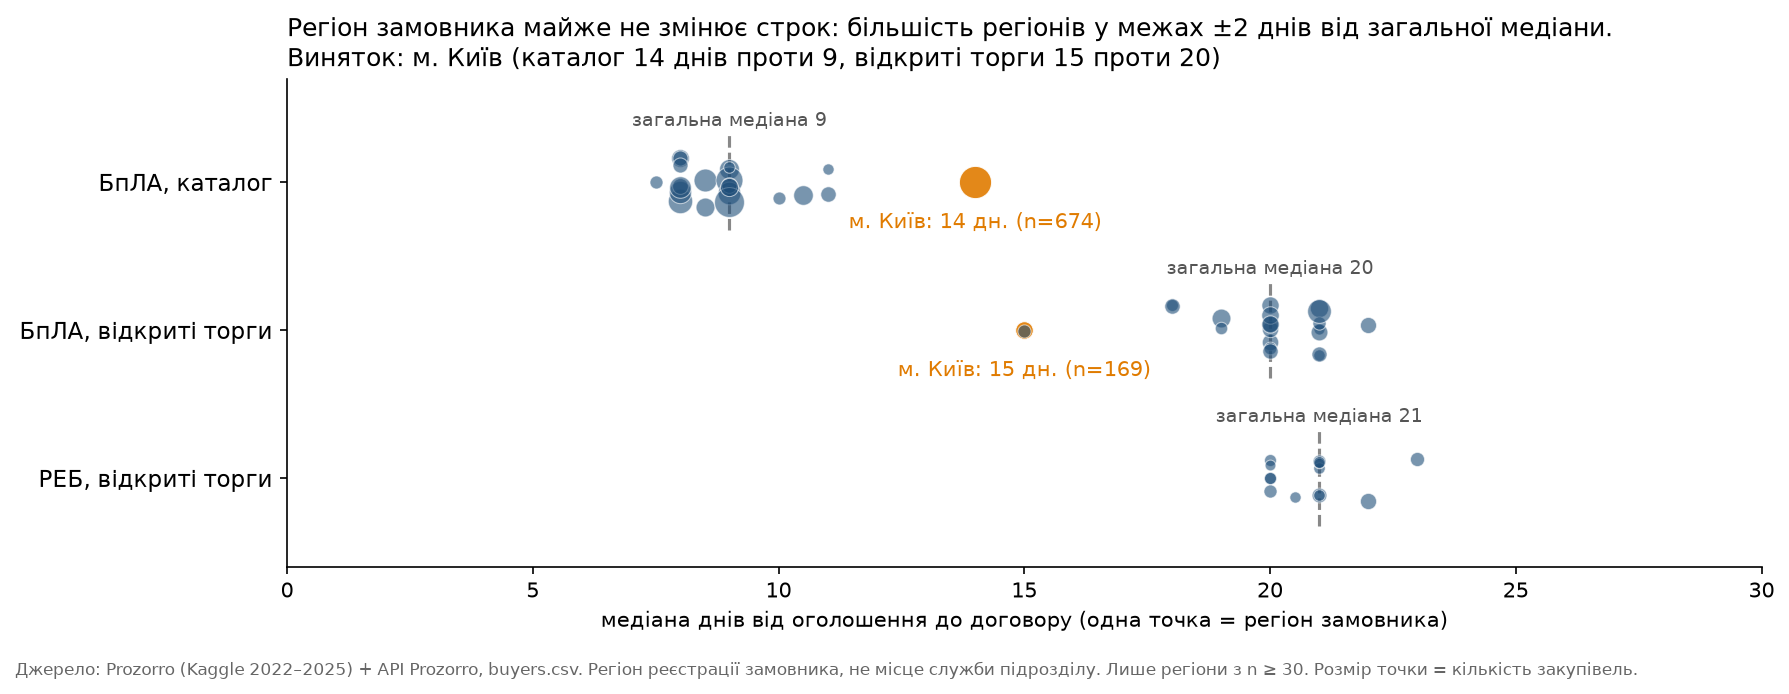

In [5]:
groups = ['БпЛА, каталог', 'БпЛА, відкриті торги', 'РЕБ, відкриті торги']
nat = {'БпЛА, каталог': 9, 'БпЛА, відкриті торги': 20, 'РЕБ, відкриті торги': 21}
fig, ax = plt.subplots(figsize=(12, 4.6), dpi=150)
rng = np.random.default_rng(1)
for i, gname in enumerate(groups):
    y = len(groups) - 1 - i
    d = r[r.grp == gname]
    ax.plot([nat[gname]]*2, [y-0.32, y+0.32], color='#888', lw=1.5, ls='--', zorder=1)
    for _, row in d.iterrows():
        k = row.region == 'м. Київ'
        jit = 0 if k else rng.uniform(-0.18, 0.18)
        ax.scatter(row.med, y+jit, s=row.n/3+15, color='#E07B00' if k else '#1F4E79',
                   alpha=0.9 if k else 0.6, edgecolor='white', lw=0.5, zorder=3)
        if k:
            ax.annotate(f'м. Київ: {row.med:.0f} дн. (n={row.n})', (row.med, y), xytext=(0, -22),
                        textcoords='offset points', ha='center', fontsize=10, color='#E07B00')
    ax.text(nat[gname], y+0.38, f'загальна медіана {nat[gname]}', ha='center', fontsize=9, color='#555')
ax.set_yticks(range(len(groups))); ax.set_yticklabels(groups[::-1], fontsize=11)
ax.set_xlim(0, 30); ax.set_ylim(-0.6, 2.7)
ax.set_xlabel('медіана днів від оголошення до договору (одна точка = регіон замовника)', fontsize=10)
for s in ['top', 'right']: ax.spines[s].set_visible(False)
ax.set_title('Регіон замовника майже не змінює строк: більшість регіонів у межах ±2 днів від загальної медіани.\nВиняток: м. Київ (каталог 14 днів проти 9, відкриті торги 15 проти 20)', fontsize=12, loc='left')
fig.text(0.01, 0.01, 'Джерело: Prozorro (Kaggle 2022–2025) + API Prozorro, buyers.csv. Регіон реєстрації замовника, не місце служби підрозділу. Лише регіони з n ≥ 30. Розмір точки = кількість закупівель.', fontsize=8, color='#666')
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.savefig('../screenshots/chart4_regions.png', facecolor='white')
plt.show()

**Висновок:** у кожній групі більшість регіонів у межах ±2 днів від загальної медіани, тож P80 з таблиці можна застосовувати по всій країні. Виняток: замовники з м. Києва (каталог 14 днів проти 9, відкриті торги 15 проти 20). Причину не перевіряли.